# Which rule defines an AF488-positive cell?

One organoid of each assembloid carries AF488. A cell is counted as **migrated** when it is AF488-positive and lies past the junction line, in the other organoid. Everything downstream therefore rests on one decision per cell: *is it AF488-positive?* This notebook compares ten ways of making that decision and asks which one is most trustworthy.

**The classic approaches** (as used in flow cytometry, CellProfiler, QuPath):

- **Negative-control percentile.** Take cells known not to carry the label and put the cut at, say, their 99th percentile. By construction about 1 % of true negatives pass, so the false-positive rate is *known*. Here the negative control is the cells deep (> 300 µm past the line, > 30 µm inside the tissue) in the organoid where AF488 is not at home (`C.negatives`); where fewer than 50 cells lie that deep (a small organoid), the control moves nearer — 200, then 100 µm.
- **Local background / ring contrast.** Compare each nucleus with a ring 3–6 µm around it. A labelled cell stands out from its surroundings; a cell that is only bright because the whole area is hazy or the section is thick there does not. This is CellProfiler's and QuPath's "cell over background" idea.
- **Two-population models.** If the intensities form two humps (negative and positive), a Gaussian mixture (GMM) or Otsu's threshold on log intensity splits them without any reference population.
- **Spectral exclusion of autofluorescence.** Autofluorescent debris and dying cells are bright in every channel. A cell that is at least as bright for its ring in another channel (here AF555) as in AF488 is dropped.

**Why the current rule overcounts.** The junction analysis calls a cell positive above *median + 3 SD of the band's own cells*. The band straddles the line, so half its cells sit on the AF488 side and are mostly positive; the median and the (MAD-based) SD then describe a mixture, not a negative population. Worse, with a robust SD a cut at 3 SD passes a few % of any long-tailed negative population — haze, edge cells, autofluorescence — so cells past the line get called positive even where there are no migrants. The cut also moves with how much of each organoid the band happens to cover.

**The reference we do not trust much.** Quillan clicked AF488-positive cells near the line and past it on about 12 samples. By his own account the clicks are noisy and incomplete. So they are used here as a *weak* reference (section 3), and the **label-free** criteria (section 2) count at least as much. No rule is tuned on the clicks.

**Sections.** 1. what the intensities look like; 2. a label-free scoreboard; 3. agreement with the clicks; 4. a look at the cells themselves; 5. one summary table and how to choose.

In [1]:
from pathlib import Path
import ssl
import sys
import warnings
import zlib

try:
    ssl.create_default_context()
except ssl.SSLError:
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "microscopy_viewer").is_dir())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

import count_common as C
from microscopy_viewer import loaders

cells, meta = C.load_all()
LABEL = C.label_channel(meta)
CHANNELS = meta["channels"].iloc[0]
OTHERS = [c for c in CHANNELS if c != LABEL]
RULES = C.rules(CHANNELS, LABEL)
NAMES = sorted(cells)
BAND = "first"
print(f"label channel {LABEL}; other measured channels {OTHERS}; {len(RULES)} rules; "
      f"line gap {C.GAP_UM:g} µm; negative control > {C.DEEP_UM:g} µm past the line")

30 of 30 annotated samples measured, 919,868 cells; bands: first 30, second 27, automatic 26
label channel AF488; other measured channels ['AF555']; 10 rules; line gap 2 µm; negative control > 300 µm past the line


Every rule is applied to every sample, once with the first annotator's band and line and once with Quillan's (the rules that use the band or the negative control depend on which line is used). The result is one positive / negative call per cell, per rule, per band.

The table counts, per sample, the cells in each zone used below, and the share of cells with **no ring**: where nuclei are packed, no pixel 3–6 µm around a nucleus is free of other cells, so there is no local background and no ring contrast. The ring-contrast rules (as written in `count_common`) treat those cells as negative, so they can never be called positive by those rules — keep this in mind when reading their numbers.

Two more things to know about the rules as implemented: the GMM and Otsu cuts are fitted on all cells of the section (both organoids), and the autofluorescence exclusion compares against the only other measured channel, AF555 — itself a label, not an empty channel — so it may also drop genuinely double-bright cells.

In [2]:
POS = {}            # (band, rule) -> {sample: bool per cell}
for band in ("first", "second"):
    for rule, f in RULES.items():
        POS[(band, rule)] = {n: np.asarray(f(cells[n], band), bool) for n in NAMES if f"in {band}" in cells[n]}


def length_mm(name, band):
    return meta.loc[name, "lengths (um)"].get(band, np.nan) / 1000


def control(df, band=BAND):
    # The negative control the rules use: > 300 µm past the line, or 200 / 100 µm where too few cells lie that deep.
    for deep in (C.DEEP_UM, 200.0, 100.0):
        neg = C.negatives(df, LABEL, band, deep)
        if neg.sum() >= 50:
            return neg
    return np.zeros(len(df), bool)


def zones(df, band=BAND):
    # Home side near the line, just past it, past it up to 300 µm, and the negative control.
    away = C.away_distance(df, LABEL, band)
    beside = df[f"beside {band}"].to_numpy()
    return {"home (−300…−2 µm)": beside & (away >= -300) & (away < -C.GAP_UM),
            "just past (2…50 µm)": beside & (away > C.GAP_UM) & (away <= 50),
            "past (2…300 µm)": beside & (away > C.GAP_UM) & (away <= C.DEEP_UM),
            "negative control": control(df, band)}


zone_table = pd.DataFrame({C.short(n): {**{z: int(m.sum()) for z, m in zones(cells[n]).items()},
                           "% with no ring": round(100 * float(np.isnan(C.contrast(cells[n], LABEL)).mean()), 1)}
              for n in NAMES}).T
zone_table.astype({c: int for c in zone_table.columns[:-1]})

,home (−300…−2 µm),just past (2…50 µm),past (2…300 µm),negative control,% with no ring
019-018_s10,3602,485,3431,5300,0.0
020-019_s4,8253,1230,6403,7377,0.0
026-025_s4,4970,996,7131,42900,0.0
026-025_s8,5905,1166,7892,63117,0.0
027-026_s5,2175,400,3039,5964,0.0
031-030_s7,1656,249,1588,527,0.0
033-032_s12,7649,1371,9850,11289,0.0
034-033_s13,6283,1184,8858,9059,0.0
034-033_s17,4059,737,6503,7764,0.0
034-033_s3,7094,1009,8087,15335,0.0


## 1. What the intensities look like

For two or three samples: the AF488 intensity of each cell (nucleus grown by 3 µm, mean, raw — the reference measurement) on a log scale, and its **ring contrast** (cell over its 3–6 µm ring), split into three groups:

- **home** — cells on the AF488 side, up to 300 µm from the line;
- **away** — cells on the other side, up to 300 µm past the line (this is where migrants are);
- **negative control** — cells more than 300 µm into the other organoid.

**How to read it.** Each curve is normalised to its own area, so the groups compare by shape, not by size. A good positivity cut sits where the negative control has run out but the home side still has most of its cells. The vertical lines are the cuts of the rules that come down to one number for this sample (dashed: intensity rules; dotted: contrast rules). The GMM cut is the dimmest cell above the sample's median that it called positive (the GMM gives a probability, not a cut; when its brighter component is also the wider one it can claim a few very dim cells too, which are ignored here). The contrast histograms leave out cells with no ring.

Two things to look for. If the whole grey curve sits left of the orange one (not just lacking its bright tail), the background itself changes with distance from the line, and a cut taken from the negative control on raw intensity will be too low near the line — ring contrast is meant to cancel exactly that. And if the green (home) curve is not the brighter one in its upper tail, the home side may have been called wrong for that sample; every zone in this notebook depends on it. Rules not drawn — the median-filtered 7 SD rule and the autofluorescence exclusion — work on another measurement or on several channels at once.

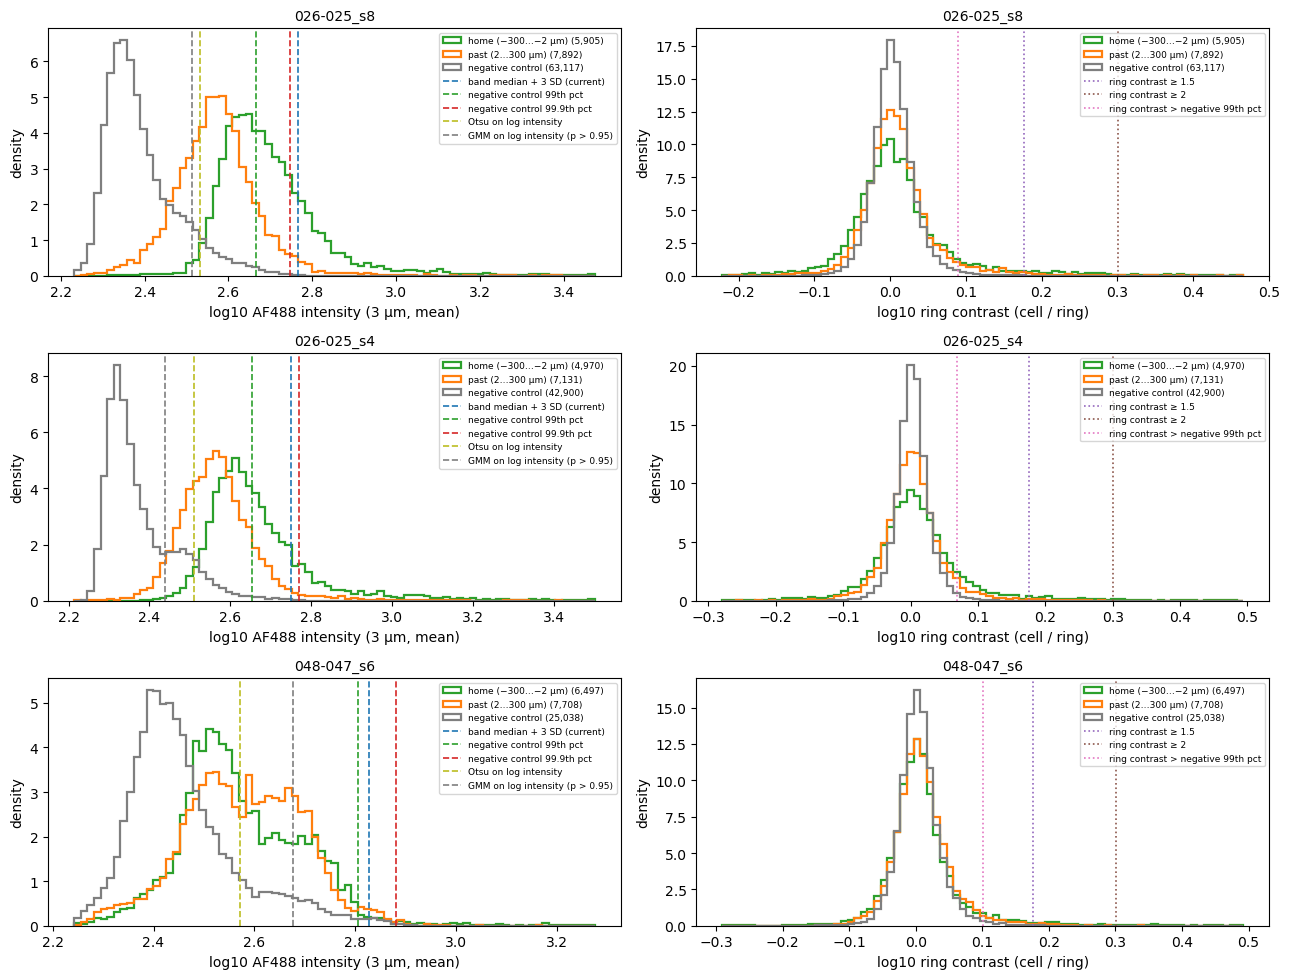

In [3]:
def intensity_cuts(df, band=BAND):
    v = df[C.column(LABEL)].to_numpy(float)
    neg = control(df, band) & np.isfinite(v)
    centre, spread = C.ja.robust_centre_and_spread(v[df[f"in {band}"].to_numpy()])
    out = {"band median + 3 SD (current)": centre + 3 * spread}
    if neg.sum() >= 50:
        out["negative control 99th pct"] = np.percentile(v[neg], 99)
        out["negative control 99.9th pct"] = np.percentile(v[neg], 99.9)
    from skimage.filters import threshold_otsu
    logs = np.log1p(np.clip(v, 0, None))
    out["Otsu on log intensity"] = np.expm1(threshold_otsu(logs[np.isfinite(logs)]))
    gmm = POS[(band, "GMM on log intensity (p > 0.95)")][df.attrs["name"]]
    if gmm.any():
        upper = gmm & (v > np.nanmedian(v))   # the GMM can also claim a few very dim cells; ignore those
        if upper.any():
            out["GMM on log intensity (p > 0.95)"] = np.nanmin(v[upper])
    return out


def contrast_cuts(df, band=BAND):
    c = C.contrast(df, LABEL)
    neg = control(df, band) & np.isfinite(c)
    out = {"ring contrast ≥ 1.5": 1.5, "ring contrast ≥ 2": 2.0}
    if neg.sum() >= 50:
        out["ring contrast > negative 99th pct"] = np.percentile(c[neg], 99)
    return out


for n in NAMES:
    cells[n].attrs["name"] = n
SHOW = sorted(NAMES, key=lambda n: -int(control(cells[n]).sum()))[:3]
GROUP_COLOURS = {"home (−300…−2 µm)": "tab:green", "past (2…300 µm)": "tab:orange", "negative control": "tab:grey"}
cut_colours = dict(zip(RULES, plt.cm.tab10(np.linspace(0, 1, 10))))

fig, axes = plt.subplots(len(SHOW), 2, figsize=(13, 3.3 * len(SHOW)), squeeze=False)
for row, n in zip(axes, SHOW):
    df = cells[n]
    z = zones(df)
    v = np.log10(np.clip(df[C.column(LABEL)].to_numpy(float), 1, None))
    c = np.log10(np.clip(C.contrast(df, LABEL), 0.1, None))      # NaN (no ring) left out of the histogram
    for ax, values, cuts, ls, xlabel in [
            (row[0], v, intensity_cuts(df), "--", f"log10 {LABEL} intensity (3 µm, mean)"),
            (row[1], c, contrast_cuts(df), ":", "log10 ring contrast (cell / ring)")]:
        bins = np.linspace(np.nanpercentile(values, 0.1), np.nanpercentile(values, 99.9), 80)
        for g, colour in GROUP_COLOURS.items():
            shown = z[g] & np.isfinite(values)
            if shown.sum():
                ax.hist(values[shown], bins, density=True, histtype="step", lw=1.6, color=colour,
                        label=f"{g} ({int(shown.sum()):,})")
        for rule, cut in cuts.items():
            if np.isfinite(cut) and cut > 0:
                ax.axvline(np.log10(cut), ls=ls, color=cut_colours[rule], lw=1.2, label=rule)
        ax.set_xlabel(xlabel); ax.set_ylabel("density")
        ax.set_title(C.short(n), fontsize=10)
        ax.legend(fontsize=6.5, loc="upper right")
fig.tight_layout()

## 2. Label-free scoreboard (first annotator's band)

Six things a good rule should do, none of which needs the clicks:

- **(a) Few positives in the negative control** — the false-positive rate. For the rules that *set* their cut on the negative control, measuring the rate on the same cells would be circular (the 99th-percentile rule gets exactly 1 % by construction). So the negative-control cells of each sample are split in two halves; the cut is computed on one half and the rate measured on the other, and then the other way round. Two splits are shown: **at random**, and **by position** (the two halves of the control region along its long axis), which is stricter — it asks whether the cut carries over to another part of the tissue. The other rules do not look at the negative control, so for them the rate is simply measured on all of it.
- **(b) The home side clearly positive** — % positive among cells on the AF488 side within 300 µm of the line. This is where the AF488 cells are, so it should stand well above the false-positive floor (a); how high it can be depends on how densely the organoid is labelled, which is why it is not scored on its own.
- **(c) A sharp drop at the line** — % positive just past the line (2–50 µm), and the **step**: (b) / (c). Migrants are few, so a good rule drops steeply at the line; a rule that calls haze or spill-over positive drops gently.
- **(d) Agreement between annotators** — Lin's concordance (CCC) of the per-sample positive counts in the first and in the second band. A rule whose result depends on who drew the band is fragile.
- **(e) Spread across samples** — coefficient of variation (SD / mean) of % positive in the band. True biology varies between samples, so lower is not automatically better, but a rule with a very large spread is often reacting to imaging differences.
- **(f) Do rules rank the samples alike?** — Spearman correlation, across samples, of the migrated count (positive cells past the line, up to 300 µm, per mm of line) between every pair of rules.

In [4]:
NEG_RULES = {   # the rules that set their cut on the negative control: (value, percentile, drop autofluorescence)
    "negative control 99th pct": ("intensity", 99.0, False),
    "negative control 99.9th pct": ("intensity", 99.9, False),
    "ring contrast > negative 99th pct": ("contrast", 99.0, False),
    "ring contrast > negative 99th pct, no autofluorescence": ("contrast", 99.0, True),
}


def neg_rule(df, band, kind, q, no_af, train):
    # The negative-control rules of count_common, with the cut set on the *train* cells only.
    values = C.contrast(df, LABEL) if kind == "contrast" else df[C.column(LABEL)].to_numpy(float)
    ok = train & np.isfinite(values)
    if ok.sum() < 25:
        return np.zeros(len(df), bool)
    out = values > np.percentile(values[ok], q)
    return C.rule_not_autofluorescent(df, LABEL, band, OTHERS, out) if no_af else out


def halves(df, neg, how, seed):
    idx = np.flatnonzero(neg)
    if how == "random":
        idx = np.random.default_rng(seed).permutation(idx)
        a = idx[: len(idx) // 2]
    else:
        xy = df[["y (um)", "x (um)"]].to_numpy()[idx]
        xy = xy - xy.mean(0)
        axis = np.linalg.svd(xy, full_matrices=False)[2][0] if len(idx) > 2 else np.array([1.0, 0.0])
        a = idx[xy @ axis <= np.median(xy @ axis)]
    A = np.zeros(len(df), bool); A[a] = True
    return A, neg & ~A


fp_rows = []
for n in NAMES:
    df = cells[n]
    neg = control(df)
    if neg.sum() < 50:
        continue
    split = {how: halves(df, neg, how, seed=zlib.crc32(n.encode())) for how in ("random", "position")}
    for rule in RULES:
        p_all = POS[(BAND, rule)][n]
        row = {"name": n, "rule": rule, "negatives": int(neg.sum()), "in-sample": p_all[neg].mean()}
        for how, (A, B) in split.items():
            if rule in NEG_RULES:
                cut_a, cut_b = (neg_rule(df, BAND, *NEG_RULES[rule], train=t) for t in (A, B))
                row[how] = 0.5 * (cut_a[B].mean() + cut_b[A].mean())
            else:
                row[how] = p_all[neg].mean()
        fp_rows.append(row)
fp = pd.DataFrame(fp_rows)
fp_table = (100 * fp.groupby("rule", sort=False)[["in-sample", "random", "position"]].median()).round(2)
fp_table.columns = ["% FP in-sample", "% FP held out (random)", "% FP held out (position)"]
print(f"median over {fp['name'].nunique()} samples with ≥ 50 negative-control cells")
fp_table

median over 30 samples with ≥ 50 negative-control cells


,% FP in-sample,% FP held out (random),% FP held out (position)
rule,,,
band median + 3 SD (current),0.54,0.54,0.54
"band median + 7 SD, median filter",0.03,0.03,0.03
negative control 99th pct,1.01,1.04,2.13
negative control 99.9th pct,0.11,0.13,0.67
ring contrast ≥ 1.5,0.07,0.07,0.07
ring contrast ≥ 2,0.00,0.00,0.00
ring contrast > negative 99th pct,1.01,1.04,1.32
GMM on log intensity (p > 0.95),0.43,0.43,0.43
Otsu on log intensity,30.69,30.69,30.69


**How to read it.** The columns are % of negative-control cells called positive (median over samples). For the negative-control rules the in-sample number is fixed by construction (1 % or 0.1 %); the held-out numbers say whether the promise holds on cells the cut was not set on. A held-out rate much above the in-sample one, especially for the split by position, means the negative control is not uniform — the cut is learning the local background of one part of the section. For the other rules the three columns are the same number: their false-positive rate.

Next, (b) and (c): % positive by distance from the line, and the step at the line.

In [5]:
side_rows = []
for n in NAMES:
    z = zones(cells[n])
    for rule in RULES:
        p = POS[(BAND, rule)][n]
        side_rows.append({"name": n, "rule": rule,
                          **{f"% {k}": 100 * p[m].mean() if m.sum() else np.nan for k, m in z.items()}})
side = pd.DataFrame(side_rows)
side["step"] = side["% home (−300…−2 µm)"] / side["% just past (2…50 µm)"].replace(0, np.nan)
side_table = side.groupby("rule", sort=False)[["% home (−300…−2 µm)", "% just past (2…50 µm)", "% past (2…300 µm)", "step"]].median()
side_table.round(2)

,% home (−300…−2 µm),% just past (2…50 µm),% past (2…300 µm),step
rule,,,,
band median + 3 SD (current),3.26,1.39,1.45,2.02
"band median + 7 SD, median filter",1.99,0.43,0.31,2.38
negative control 99th pct,4.71,2.30,2.53,1.93
negative control 99.9th pct,2.00,0.67,0.44,1.73
ring contrast ≥ 1.5,1.18,0.27,0.20,1.52
ring contrast ≥ 2,0.28,0.00,0.02,0.95
ring contrast > negative 99th pct,4.71,2.89,2.27,1.17
GMM on log intensity (p > 0.95),3.06,1.49,1.09,1.36
Otsu on log intensity,37.64,34.29,51.62,0.99


**Profile across the line.** % positive in 25 µm steps of distance from the line (negative: AF488's home side; positive: past the line into the other organoid), median over samples. A good rule is a high plateau on the left, a cliff at 0, and a low floor on the right that stays low far from the line (the far floor is the false-positive rate; anything above it close to the line can be migrants).

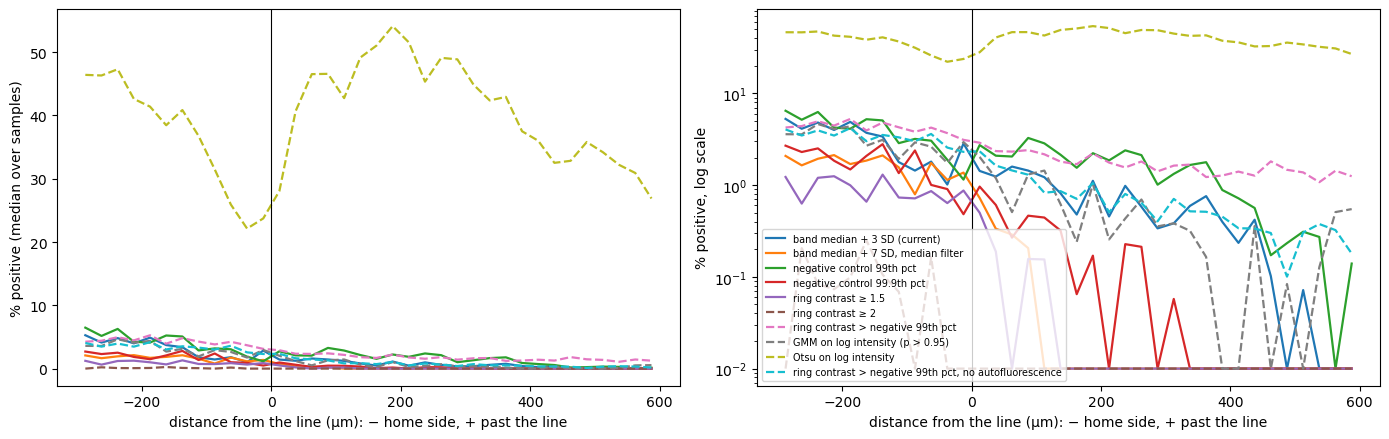

In [6]:
EDGES = np.arange(-300, 625, 25)
centres = (EDGES[:-1] + EDGES[1:]) / 2
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for i, rule in enumerate(RULES):
    curves = []
    for n in NAMES:
        df = cells[n]
        away = C.away_distance(df, LABEL, BAND)
        ok = df[f"beside {BAND}"].to_numpy()
        which = np.digitize(away, EDGES) - 1
        p = POS[(BAND, rule)][n]
        curves.append([100 * p[ok & (which == k)].mean() if (ok & (which == k)).sum() >= 20 else np.nan
                       for k in range(len(centres))])
    curve = np.nanmedian(np.array(curves), axis=0)
    style = dict(color=cut_colours[rule], lw=1.6, ls="-" if i < 5 else "--", label=rule)
    axes[0].plot(centres, curve, **style)
    axes[1].plot(centres, np.clip(curve, 1e-2, None), **style)
for ax in axes:
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel("distance from the line (µm): − home side, + past the line")
axes[0].set_ylabel("% positive (median over samples)")
axes[1].set_yscale("log"); axes[1].set_ylabel("% positive, log scale")
axes[1].legend(fontsize=7, loc="lower left")
fig.tight_layout()

**(d) and (e).** Positive cells in the band, per sample, with the first and with the second annotator's band; their concordance; and the spread of % positive in the first band across samples.

In [7]:
band_rows = []
for n in NAMES:
    df = cells[n]
    for rule in RULES:
        row = {"name": n, "rule": rule}
        for band in ("first", "second"):
            if n in POS[(band, rule)]:
                inside = df[f"in {band}"].to_numpy()
                row[f"positive in {band}"] = int(POS[(band, rule)][n][inside].sum())
                row[f"% in {band}"] = 100 * POS[(band, rule)][n][inside].mean() if inside.any() else np.nan
        band_rows.append(row)
bands = pd.DataFrame(band_rows)
if "positive in second" not in bands:
    bands["positive in second"] = np.nan
agree = bands.groupby("rule", sort=False).apply(include_groups=False, func=lambda g: pd.Series({
    "band CCC first vs second": C.ccc(g["positive in first"], g["positive in second"]),
    "% positive in band (median)": g["% in first"].median(),
    "CV of % in band": g["% in first"].std() / g["% in first"].mean() if g["% in first"].mean() else np.nan,
    "samples": int(g["positive in second"].notna().sum())}))
agree.round(2)

,band CCC first vs second,% positive in band (median),CV of % in band,samples
rule,,,,
band median + 3 SD (current),0.99,1.52,1.18,27.0
"band median + 7 SD, median filter",0.98,0.32,1.05,27.0
negative control 99th pct,0.91,2.45,1.12,27.0
negative control 99.9th pct,0.89,0.44,1.81,27.0
ring contrast ≥ 1.5,0.99,0.20,1.06,27.0
ring contrast ≥ 2,0.99,0.03,1.66,27.0
ring contrast > negative 99th pct,0.98,2.35,0.61,27.0
GMM on log intensity (p > 0.95),1.00,1.16,2.10,27.0
Otsu on log intensity,1.00,51.01,0.59,27.0


**(f) Do the rules rank the samples alike?** Each sample's migrated count (positive cells past the first annotator's line, up to 300 µm, per mm of line) under each rule; the heatmap is the Spearman correlation between rules across samples. A block of rules that correlate highly agree on *which samples have more migration*, even if their absolute counts differ — and that ranking is what a genotype comparison uses. A rule that correlates poorly with everything else is either seeing something the others miss, or noise. With few samples these correlations are very uncertain.

migrated cells per mm, median over samples:
band median + 3 SD (current)                                79.6
band median + 7 SD, median filter                           11.1
negative control 99th pct                                  120.7
negative control 99.9th pct                                 22.8
ring contrast ≥ 1.5                                          7.8
ring contrast ≥ 2                                            1.1
ring contrast > negative 99th pct                           94.3
GMM on log intensity (p > 0.95)                             66.4
Otsu on log intensity                                     2383.6
ring contrast > negative 99th pct, no autofluorescence      45.4


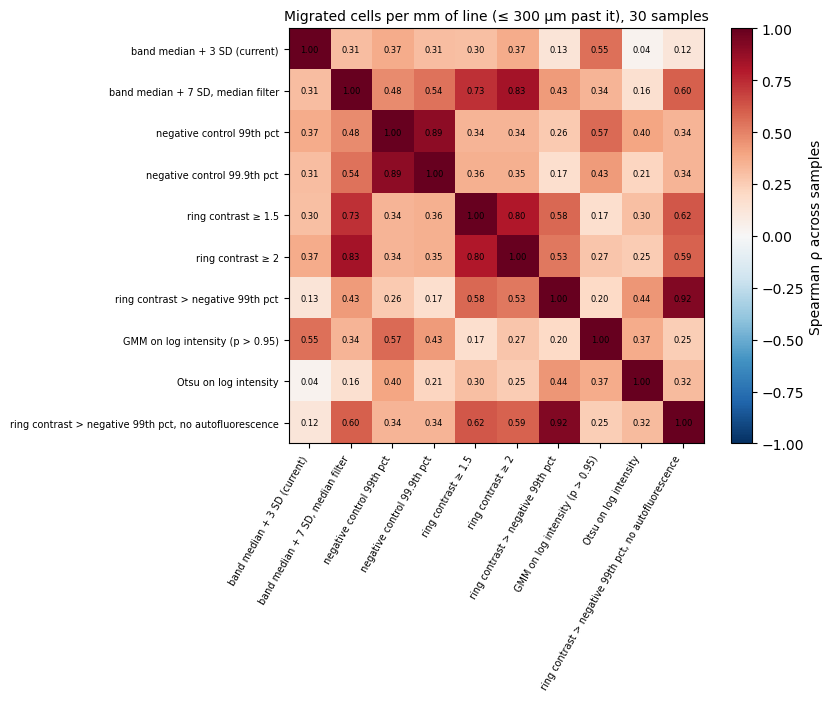

In [8]:
crossed = pd.DataFrame({rule: {n: POS[(BAND, rule)][n][C.region(cells[n], "crossed", BAND, LABEL, 300)].sum()
                                  / length_mm(n, BAND) for n in NAMES} for rule in RULES})
rho = crossed.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(rho.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(rho))); ax.set_xticklabels(rho.columns, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(rho))); ax.set_yticklabels(rho.index, fontsize=7)
for i in range(len(rho)):
    for j in range(len(rho)):
        if np.isfinite(rho.iat[i, j]):
            ax.text(j, i, f"{rho.iat[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, label="Spearman ρ across samples")
ax.set_title(f"Migrated cells per mm of line (≤ 300 µm past it), {len(crossed)} samples", fontsize=10)
fig.tight_layout()
rank_agree = rho.where(~np.eye(len(rho), dtype=bool)).median()
print("migrated cells per mm, median over samples:")
print(crossed.median().round(1).to_string())

**Putting the label-free criteria together.** Each rule is ranked on three criteria — held-out false-positive rate by position (low is good), step at the line (high), concordance between annotators (high) — and the ranks are averaged; ties go to the lower held-out false-positive rate. % positive on the home side (b), the spread across samples (e) and the agreement with the other rules (f) are shown but left out of the score: (b) rewards leniency, and a rule can be right *and* differ from the rest. The top rule is the one examined cell by cell in section 4. This is a heuristic summary, not a proof: read the columns, not only the score.

In [9]:
board = pd.concat([fp_table, side_table, agree.drop(columns="samples"),
                   rank_agree.rename("median ρ with other rules")], axis=1)
crit = {"% FP held out (position)": True, "step": False, "band CCC first vs second": False}
ranks = pd.concat([board[c].rank(ascending=low, na_option="bottom") for c, low in crit.items()], axis=1)
board["label-free rank (mean)"] = ranks.mean(axis=1)
board = board.sort_values(["label-free rank (mean)", "% FP held out (position)"])
BEST = board.index[0]
print("best on the label-free criteria:", BEST)
board.round(2)

best on the label-free criteria: band median + 7 SD, median filter


,% FP in-sample,% FP held out (random),% FP held out (position),% home (−300…−2 µm),% just past (2…50 µm),% past (2…300 µm),step,band CCC first vs second,% positive in band (median),CV of % in band,median ρ with other rules,label-free rank (mean)
"band median + 7 SD, median filter",0.03,0.03,0.03,1.99,0.43,0.31,2.38,0.98,0.32,1.05,0.48,3.33
ring contrast ≥ 1.5,0.07,0.07,0.07,1.18,0.27,0.20,1.52,0.99,0.20,1.06,0.36,4.00
GMM on log intensity (p > 0.95),0.43,0.43,0.43,3.06,1.49,1.09,1.36,1.00,1.16,2.10,0.34,4.00
band median + 3 SD (current),0.54,0.54,0.54,3.26,1.39,1.45,2.02,0.99,1.52,1.18,0.31,4.00
ring contrast ≥ 2,0.00,0.00,0.00,0.28,0.00,0.02,0.95,0.99,0.03,1.66,0.37,5.33
"ring contrast > negative 99th pct, no autofluorescence",0.41,0.41,0.52,4.17,1.96,1.02,1.89,0.97,1.05,0.76,0.34,5.67
negative control 99th pct,1.01,1.04,2.13,4.71,2.30,2.53,1.93,0.91,2.45,1.12,0.37,7.00
Otsu on log intensity,30.69,30.69,30.69,37.64,34.29,51.62,0.99,1.00,51.01,0.59,0.30,7.00
negative control 99.9th pct,0.11,0.13,0.67,2.00,0.67,0.44,1.73,0.89,0.44,1.81,0.35,7.33
ring contrast > negative 99th pct,1.01,1.04,1.32,4.71,2.89,2.27,1.17,0.98,2.35,0.61,0.43,7.33


## 3. Against Quillan's clicks (a weak reference)

The clicks are compared with each rule in the region Quillan counted: cells within 50 µm of *his* line on either side, or past it (`C.region(df, "near + crossed", "second", …)`; the first annotator's line where he drew none). Each click is matched to the nearest cell within 7 µm, one to one.

- **TP** — rule-positive cells in the region that were clicked;
- **FP** — rule-positive cells in the region that were not clicked;
- **FN** — clicks in the region whose cell the rule did not call, plus clicks that matched no cell (a missed segmentation counts against every rule alike).

From these: **precision** TP / (TP + FP), **recall** TP / (TP + FN), and **F1**, their harmonic mean, pooled over samples. Then, per sample, the rule's count per mm of line against the clicks per mm: Spearman (same ranking?), CCC (same numbers?) and the median ratio (rule / clicks).

**Caution.** The clicks are incomplete. A low precision may mean the rule finds cells Quillan did not click, not that it is wrong — section 4 lets you look. Recall is the more trustworthy of the two: a clicked cell is at least probably positive.

In [10]:
dots = C.load_dots(cells, meta)
CLICKED = sorted(dots["name"].unique()) if len(dots) else []
print(f"{len(CLICKED)} samples with clicks, {len(dots)} clicks, {int(dots['matched'].sum()) if len(dots) else 0} matched to a cell")


def click_region(n):
    # Quillan's region, its band, the clicks in it (with their cell, -1 if none).
    df = cells[n]
    band = "second" if f"in second" in df else "first"
    reg = C.region(df, "near + crossed", band, LABEL)
    d = dots[dots["name"] == n].copy()
    sign = -1.0 if C.home_is_band_side(df, LABEL, band) else 1.0
    away = sign * d[f"from {band} (um)"].to_numpy()
    own = d[f"beside {band}"].to_numpy().astype(bool) & ((away > C.GAP_UM) | (np.abs(away) <= 50))
    cell = d["cell"].to_numpy()
    d["in region"] = np.where(cell >= 0, reg[np.clip(cell, 0, None)], own)
    return band, reg, d[d["in region"]]


click_rows = []
for n in CLICKED:
    band, reg, d = click_region(n)
    clicked = cells[n]["clicked"].to_numpy()
    cell = d["cell"].to_numpy()
    for rule in RULES:
        p = POS[(band, rule)][n]
        pr = p & reg
        click_rows.append({"name": n, "rule": rule, "band": band, "mm": length_mm(n, band),
                           "TP": int((pr & clicked).sum()), "FP": int((pr & ~clicked).sum()),
                           "FN": int(((cell < 0) | ~p[np.clip(cell, 0, None)]).sum()),
                           "positive": int(pr.sum()), "clicks": len(d)})
clicks = pd.DataFrame(click_rows)
if clicks.empty:
    print("No clicks among the samples measured so far: section 3 skipped.")

12 samples with clicks, 822 clicks, 710 matched to a cell


In [11]:
def against_clicks(g):
    tp, fp, fn = g["TP"].sum(), g["FP"].sum(), g["FN"].sum()
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    rule_mm, click_mm = g["positive"] / g["mm"], g["clicks"] / g["mm"]
    return pd.Series({"precision": precision, "recall": recall,
                      "F1": 2 * precision * recall / (precision + recall) if precision + recall else np.nan,
                      "Spearman vs clicks/mm": stats.spearmanr(rule_mm, click_mm).statistic if len(g) >= 3 else np.nan,
                      "CCC vs clicks/mm": C.ccc(rule_mm, click_mm),
                      "median ratio rule/clicks": (rule_mm / click_mm.replace(0, np.nan)).median()})


if not clicks.empty:
    click_table = clicks.groupby("rule", sort=False).apply(against_clicks, include_groups=False)
    print(f"{clicks['name'].nunique()} samples, {int(clicks.groupby('name')['clicks'].first().sum())} clicks in the region")
    display(click_table.round(2))
    per_sample = clicks.assign(per_mm=clicks["positive"] / clicks["mm"]).pivot(index="name", columns="rule", values="per_mm")
    per_sample.insert(0, "clicks / mm", clicks.groupby("name")["clicks"].first() / clicks.groupby("name")["mm"].first())
    per_sample.index = [C.short(n) for n in per_sample.index]
    print("per sample, cells per mm of line in Quillan's region:")
    display(per_sample[["clicks / mm", *[r for r in dict.fromkeys([BEST, "band median + 3 SD (current)"]) if r in per_sample]]].round(1))
else:
    click_table = pd.DataFrame(index=list(RULES), columns=["precision", "recall", "F1", "Spearman vs clicks/mm",
                                                            "CCC vs clicks/mm", "median ratio rule/clicks"], dtype=float)

12 samples, 603 clicks in the region


,precision,recall,F1,Spearman vs clicks/mm,CCC vs clicks/mm,median ratio rule/clicks
rule,,,,,,
band median + 3 SD (current),0.07,0.57,0.13,0.03,0.01,7.02
"band median + 7 SD, median filter",0.29,0.55,0.38,0.73,0.28,1.44
negative control 99th pct,0.05,0.59,0.09,0.28,0.03,6.86
negative control 99.9th pct,0.14,0.43,0.21,0.18,0.12,1.48
ring contrast ≥ 1.5,0.20,0.31,0.25,0.53,0.33,0.99
ring contrast ≥ 2,0.42,0.16,0.23,0.65,0.42,0.12
ring contrast > negative 99th pct,0.06,0.52,0.10,0.55,0.04,6.15
GMM on log intensity (p > 0.95),0.01,0.59,0.02,0.20,0.00,2.69
Otsu on log intensity,0.01,0.81,0.01,0.06,0.00,136.50


per sample, cells per mm of line in Quillan's region:


rule,clicks / mm,"band median + 7 SD, median filter",band median + 3 SD (current)
020-019_s4,27.4,47.6,257.2
026-025_s4,70.6,246.3,560.4
026-025_s8,74.4,277.6,532.6
031-030_s7,53.4,16.1,7.4
033-032_s12,46.2,101.4,152.7
034-033_s13,46.9,77.9,167.2
034-033_s17,28.3,28.3,77.2
039-038_s5,37.9,47.6,278.1
045-044_s15,26.2,7.3,61.9
048-047_s6,31.6,51.6,217.9


**How to read it.** Precision and recall pull in opposite directions: a lenient rule clicks everything (recall near 1, precision low), a strict one only the brightest (precision high, recall low). F1 balances the two, but with incomplete clicks it rewards rules that are about as strict as Quillan was, which is not the same as being right. The per-sample columns matter more for the biology: a rule with a modest F1 but a high Spearman against the clicks ranks the samples as Quillan would, and a median ratio near 1 means it counts about as many cells.

## 4. Looking at the cells

For one or two samples with clicks, small crops (40 µm square, AF488 channel, each crop contrast-stretched on its own from its 1st to its 99.5th percentile, so **brightness cannot be compared between crops** — what matters is whether the centre nucleus stands out from its surroundings) of cells in Quillan's region, in three rows:

- **called, not clicked** — positive under the best label-free rule (above), but not clicked: either a missed click or a false positive;
- **clicked, not called** — clicked, but the rule says negative (crop centred on the click itself, so unmatched clicks are shown too): either a cell the rule misses or a doubtful click;
- **both** — for reference, what agreed positives look like.

The cross marks the cell's centre. The number above each crop is its ring contrast (cell / ring); "no ring" means the cell is so tightly packed that no ring pixels were free, "no cell" a click that matched no segmented cell.

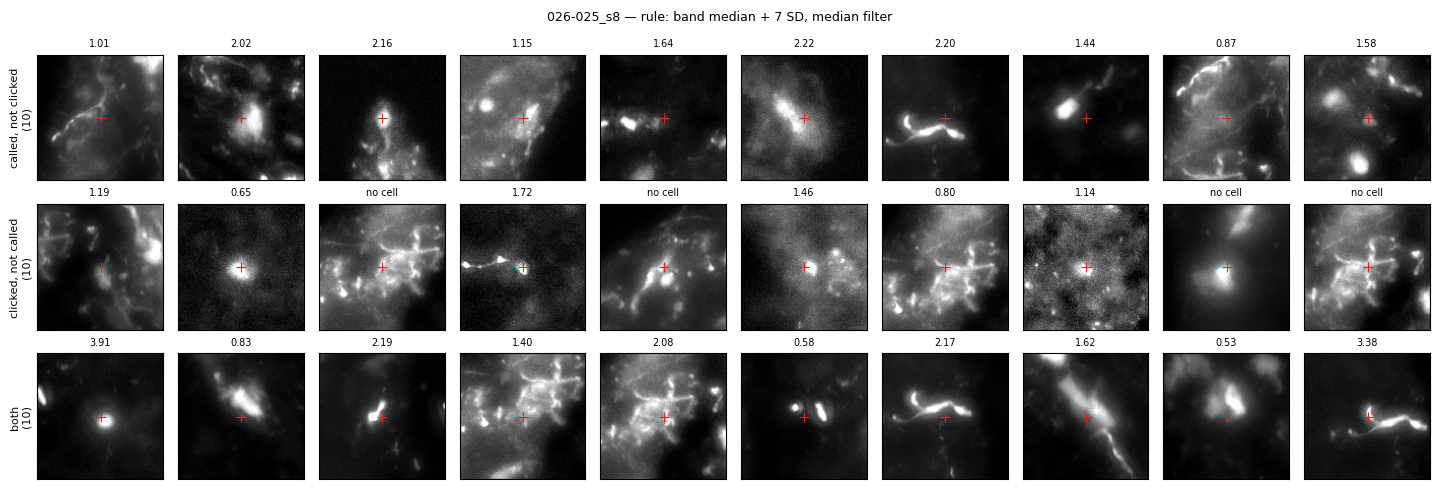

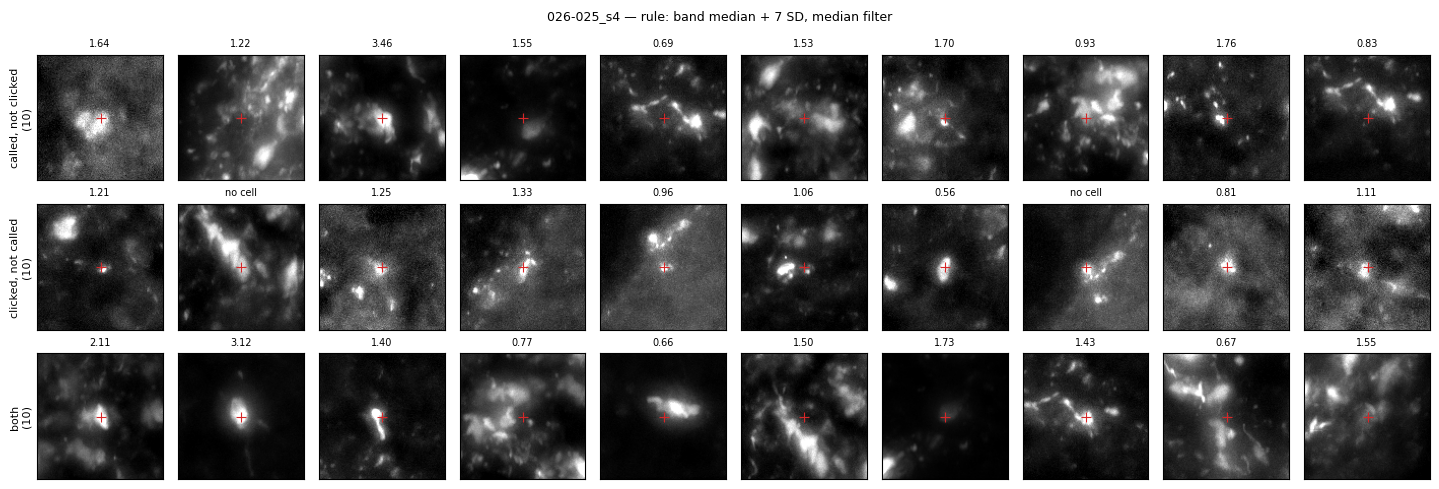

In [12]:
HALF_UM, PER_ROW = 20.0, 10


def crop(data, y, x, half):
    y, x = int(round(y)), int(round(x))
    y0, x0 = max(y - half, 0), max(x - half, 0)
    a = np.asarray(data[..., y0:y + half, x0:x + half], dtype=float)
    a = a.reshape(-1, *a.shape[-2:]).max(axis=0)
    lo, hi = np.percentile(a, [1, 99.5])
    return np.clip((a - lo) / (hi - lo if hi > lo else 1), 0, 1), (y - y0, x - x0)


def gallery(n, rule, seed=0):
    df = cells[n]
    band, reg, d = click_region(n)
    p = POS[(band, rule)][n] & reg
    clicked = df["clicked"].to_numpy()
    ratio = C.contrast(df, LABEL)
    rng = np.random.default_rng(seed)
    voxel = np.asarray(meta.loc[n, "voxel"], float)
    pick = lambda idx: rng.permutation(idx)[:PER_ROW]
    cell = d["cell"].to_numpy()
    missed = d[(cell < 0) | ~POS[(band, rule)][n][np.clip(cell, 0, None)]]
    missed = missed.iloc[pick(np.arange(len(missed)))]
    groups = {
        "called, not clicked": [(df["y"].iat[i], df["x"].iat[i], ratio[i]) for i in pick(np.flatnonzero(p & ~clicked))],
        "clicked, not called": [(r["y (um)"] / voxel[0], r["x (um)"] / voxel[1],
                                 ratio[r["cell"]] if r["cell"] >= 0 else "no cell") for _, r in missed.iterrows()],
        "both": [(df["y"].iat[i], df["x"].iat[i], ratio[i]) for i in pick(np.flatnonzero(p & clicked))],
    }
    path = Path(meta.loc[n, "path"])
    specs = loaders.load_path(path)
    try:
        spec = next(s for s in specs if LABEL in str(s.channel_name or s.name))
        data = spec.data[0] if isinstance(spec.data, (list, tuple)) else spec.data
        half = int(round(HALF_UM / voxel[0]))
        fig, axes = plt.subplots(3, PER_ROW, figsize=(1.45 * PER_ROW, 5.0), squeeze=False)
        for row, (title, items) in zip(axes, groups.items()):
            for k, ax in enumerate(row):
                ax.set_xticks([]); ax.set_yticks([])
                if k < len(items):
                    y, x, r = items[k]
                    img, (cy, cx) = crop(data, y, x, half)
                    ax.imshow(img, cmap="gray")
                    ax.plot(cx, cy, "+", color="tab:red", ms=7, mew=0.8)
                    ax.set_title(r if isinstance(r, str) else ("no ring" if not np.isfinite(r) else f"{r:.2f}"), fontsize=7)
                else:
                    ax.axis("off")
            row[0].set_ylabel(f"{title}\n({len(items)})", fontsize=8)
            row[0].axis("on"); row[0].set_xticks([]); row[0].set_yticks([])
        fig.suptitle(f"{C.short(n)} — rule: {rule}", fontsize=9)
        fig.tight_layout()
        plt.show()
    finally:
        loaders.release(path)


if clicks.empty:
    print("No clicks yet: no gallery.")
else:
    most = clicks.groupby("name")["clicks"].first().sort_values(ascending=False)
    for n in most.index[:2]:
        gallery(n, BEST)

**How to read it.** If the *called, not clicked* row is mostly crisp nuclei clearly brighter than their neighbours, the rule is finding cells Quillan skipped and its low precision against the clicks is not its fault. If it is mostly haze, edges or blobs without a nucleus shape, the rule is too lenient. If the *clicked, not called* row is mostly clear positives, the rule is too strict; if those crops look like nothing in particular, the clicks were generous.

## 5. Summary

One row per rule: the label-free numbers from section 2 and the click numbers from section 3, sorted by the label-free rank.

In [13]:
summary = pd.concat([board[["label-free rank (mean)", "% FP held out (position)", "% FP held out (random)",
                            "% home (−300…−2 µm)", "% just past (2…50 µm)", "step", "band CCC first vs second",
                            "CV of % in band", "median ρ with other rules"]],
                     click_table[["recall", "precision", "F1", "Spearman vs clicks/mm", "median ratio rule/clicks"]]], axis=1)
summary = summary.loc[board.index]
summary.insert(1, "migrated / mm (median)", crossed.median().reindex(summary.index))
print(f"{len(NAMES)} samples; {len(CLICKED)} with clicks; band for section 2: {BAND}")
summary.round(2)

30 samples; 12 with clicks; band for section 2: first


,label-free rank (mean),migrated / mm (median),% FP held out (position),% FP held out (random),% home (−300…−2 µm),% just past (2…50 µm),step,band CCC first vs second,CV of % in band,median ρ with other rules,recall,precision,F1,Spearman vs clicks/mm,median ratio rule/clicks
"band median + 7 SD, median filter",3.33,11.07,0.03,0.03,1.99,0.43,2.38,0.98,1.05,0.48,0.55,0.29,0.38,0.73,1.44
ring contrast ≥ 1.5,4.00,7.79,0.07,0.07,1.18,0.27,1.52,0.99,1.06,0.36,0.31,0.20,0.25,0.53,0.99
GMM on log intensity (p > 0.95),4.00,66.39,0.43,0.43,3.06,1.49,1.36,1.00,2.10,0.34,0.59,0.01,0.02,0.20,2.69
band median + 3 SD (current),4.00,79.58,0.54,0.54,3.26,1.39,2.02,0.99,1.18,0.31,0.57,0.07,0.13,0.03,7.02
ring contrast ≥ 2,5.33,1.09,0.00,0.00,0.28,0.00,0.95,0.99,1.66,0.37,0.16,0.42,0.23,0.65,0.12
"ring contrast > negative 99th pct, no autofluorescence",5.67,45.35,0.52,0.41,4.17,1.96,1.89,0.97,0.76,0.34,0.45,0.10,0.17,0.59,2.82
negative control 99th pct,7.00,120.68,2.13,1.04,4.71,2.30,1.93,0.91,1.12,0.37,0.59,0.05,0.09,0.28,6.86
Otsu on log intensity,7.00,2383.64,30.69,30.69,37.64,34.29,0.99,1.00,0.59,0.30,0.81,0.01,0.01,0.06,136.50
negative control 99.9th pct,7.33,22.78,0.67,0.13,2.00,0.67,1.73,0.89,1.81,0.35,0.43,0.14,0.21,0.18,1.48
ring contrast > negative 99th pct,7.33,94.32,1.32,1.04,4.71,2.89,1.17,0.98,0.61,0.43,0.52,0.06,0.10,0.55,6.15


**How to choose.** A positivity rule has one job that matters downstream: separate AF488 cells from everything else *the same way in every sample*, so that a difference in migrated counts between genotypes is biology and not imaging. In order of weight:

1. **A known, low false-positive rate that holds on held-out tissue** (column `% FP held out (position)`). Migrants are rare — a few per mm of line — while there are thousands of negative cells past the line, so even 1 % false positives can swamp the real signal. The held-out rate should be well below the migrated density it is meant to detect.
2. **A sharp step at the line** with the home side mostly positive. This is the closest thing to ground truth without labels: we know which organoid carries AF488.
3. **Robustness** — the same answer with either annotator's band (CCC), and a ranking of samples that other sensible rules share.
4. **The clicks**, last: recall against the clicks is a sanity check (a rule that misses most of what a person saw as positive is too strict), precision and F1 are only suggestive, and the gallery decides whether the disagreements are the rule's fault or the clicks'.

If two rules are close, prefer the simpler one whose false-positive rate is fixed by design (a negative-control percentile, on intensity or on ring contrast), and report migration both as counts per mm and as an excess over the false-positive floor measured deep in the other organoid.

### What it showed (21 October 2026: 30 samples, 920 000 cells; clicks on 12)

**One rule wins on both counts: median + 7 SD of the band's cells, on the median-filtered channel.** It is first on the label-free scoreboard and first against the clicks.

| rule | false positives in the negative control (held out by position) | step at the line | migrated / mm | F1 vs clicks | Spearman vs clicks / mm |
|---|---|---|---|---|---|
| median + 7 SD, median filter | **0.03 %** | **2.4** | 11 | **0.38** | **0.73** |
| ring contrast ≥ 1.5 | 0.07 % | 1.5 | 8 | 0.25 | 0.53 |
| median + 3 SD (current) | 0.54 % | 2.0 | 80 | 0.13 | 0.03 |
| ring contrast > negative 99th, no autofluorescence | 0.52 % | 1.9 | 45 | 0.17 | 0.59 |
| negative control 99th / 99.9th pct | 2.13 / 0.67 % | 1.9 / 1.7 | 121 / 23 | 0.09 / 0.21 | 0.28 / 0.18 |
| GMM / Otsu on log intensity | 0.43 / 31 % | 1.4 / 1.0 | 66 / 2 384 | 0.02 / 0.01 | 0.20 / 0.06 |

- **The current rule** calls 7× as many cells as were clicked and does not rank the samples like the clicks (Spearman 0.03).
- **The negative-control rules do not deliver their promised rate**: the 99th percentile gives 2.1 % held out by position, the 99.9th 0.67 % — the control region is not uniform (staining falls off with distance), so a cut from one part of it does not carry to another.
- **Two-population models fail**: AF488 is not bimodal over a section (Otsu calls half the cells).
- **Every step at the line is weak** (≤ 2.4): even the best rule calls ~2 % of the home side positive and 0.4 % just past the line. The AF488 label is dim and patchy per cell; no rule separates cleanly.
- The clicks agree best with the best label-free rule, but only at F1 0.38: with noisy clicks that is a ceiling on what can be shown, not proof the rule is wrong.

**Recommendation:** make *median + 7 SD, median-filtered* the analysis default for AF488, keep *ring contrast ≥ 1.5* as the check, and drop the current k = 3. Confirm by eye on the gallery of disagreements (section 4) before freezing it.